# DS201 · Bài thực hành 4: Encoder–Decoder và Attention cho dịch máy Anh → Việt

**Sinh viên:** Vũ Thiên An · **MSSV:** 24520081

Notebook làm Phần C (Bài 1–3) với cấu hình chung của đề: encoder và decoder mỗi bên 3 lớp LSTM, hidden 256, embedding 256, dropout 0.3, Adam lr = 1e-3, batch 32, tối đa 10 epoch (giữ checkpoint có ROUGE-L dev cao nhất), dùng toàn bộ small-PhoMT với câu ≤ 50 từ. Độ đo chính: ROUGE-L F1 trên tập test.

| Bài | Mô hình | Decoder |
|---|---|---|
| 1 | Encoder–Decoder LSTM | không attention |
| 2 | + Bahdanau attention | attention cộng, query là trạng thái bước trước |
| 3 | + Luong attention | global-general, query là trạng thái hiện tại, input-feeding |

**Cách chạy:** Restart Kernel → Run All. Nên chạy trên GPU (Kaggle/Colab) vì train 3 mô hình × 10 epoch trên toàn bộ dữ liệu. Dữ liệu tự tải về `data/` (không push lên GitHub). Checkpoint, lịch sử, đồ thị và bảng kết quả lưu ở `artifacts/`.

## 1. Thư viện, cấu hình và dữ liệu

In [1]:
# Cài 2 thư viện chấm điểm (Kaggle/Colab đã có sẵn torch, numpy, pandas, matplotlib)
%pip install -q rouge-score sacrebleu

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import thư viện
import hashlib, json, random, time, unicodedata, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import (
    pad_sequence, pack_padded_sequence, pad_packed_sequence,
)
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

In [3]:
# Cố định seed và chọn thiết bị
def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)

PyTorch: 2.14.1+cpu | device: cpu


In [4]:
# Cấu hình chung của Phần C (Bài 1–3)
cfg = dict(
    emb=256, hidden=256, layers=3,
    dropout=0.3, batch=32, lr=1e-3, teacher_ratio=0.5,
    epochs=10,
    max_words=50,
    vocab_limit=10000,
    min_freq=2,
    train_limit=None,   # None = toàn bộ train
    dev_limit=None,     # None = toàn bộ dev
)
for k, v in cfg.items():
    print(f'{k:14}= {v}')

emb           = 256
hidden        = 256
layers        = 3
dropout       = 0.3
batch         = 32
lr            = 0.001
teacher_ratio = 0.5
epochs        = 10
max_words     = 50
vocab_limit   = 10000
min_freq      = 2
train_limit   = None
dev_limit     = None


In [5]:
# Đường dẫn dữ liệu, thư mục lưu kết quả và id của 4 token đặc biệt
base = Path.cwd()
LAB = base/'Lab4' if (base/'Lab4').is_dir() else base
DATA = LAB/'data'
ART = LAB/'artifacts'
ART.mkdir(parents=True, exist_ok=True)
PAD, UNK, BOS, EOS = 0, 1, 2, 3
print('Dữ liệu:', DATA.name, '| kết quả lưu ở:', ART.name)

Dữ liệu: data | kết quả lưu ở: artifacts


### Tải đúng ba tệp small-PhoMT

Dữ liệu lấy trực tiếp từ thư mục trong đề gốc. Tệp đã có trên máy được kiểm tra SHA-256 trước khi dùng lại. Không thay bằng bộ chia khác hoặc dữ liệu giả khi không tải được.

In [6]:
# Danh sách tệp: tên, link tải và mã SHA-256
DATA_FILES = [{'file': 'small-train.json',
  'url': 'https://drive.google.com/uc?export=download&id=1-eG6FeF-v__rsf77iWurddahXbyjTYh5',
  'sha256': 'f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba'},
 {'file': 'small-dev.json',
  'url': 'https://drive.google.com/uc?export=download&id=1hoTd2hFwjSeFThlPm6YpN0NW5ePXS3Jc',
  'sha256': 'fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9'},
 {'file': 'small-test.json',
  'url': 'https://drive.google.com/uc?export=download&id=1_3L25SH1_jaEfOjpmpgnfMik4N3MxSyn',
  'sha256': '1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'}]

In [7]:
# Tải tệp còn thiếu, rồi kiểm tra SHA-256 của cả ba tệp
for item in DATA_FILES:
    path = DATA/item['file']
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        with urllib.request.urlopen(item['url'], timeout=90) as r:
            content = r.read()
        if hashlib.sha256(content).hexdigest() != item['sha256']:
            raise ValueError('Nguồn tải đổi hoặc trả về HTML: '+item['file'])
        path.write_bytes(content)
    if hashlib.sha256(path.read_bytes()).hexdigest() != item['sha256']:
        raise ValueError('Checksum không khớp: '+item['file'])
print('3/3 tệp dữ liệu khớp SHA-256.')

3/3 tệp dữ liệu khớp SHA-256.


### Chuẩn hóa Unicode và lọc theo độ dài

Mỗi tệp là JSON array gồm `english` và `vietnamese`. Loại BOM, chuẩn hóa NFC, chuyển chữ thường rồi tách theo khoảng trắng. Chỉ giữ cặp có cả hai phía từ 1 đến `max_words` token; không cắt cụt câu đích.

In [8]:
# Chuẩn hóa: bỏ BOM, NFC, chữ thường, tách theo khoảng trắng
def tokens(text):
    text = unicodedata.normalize('NFC', text.replace('﻿', ''))
    return text.lower().split()

print(tokens('Tôi YÊU bạn'))

['tôi', 'yêu', 'bạn']


In [9]:
# Đọc ba tệp, giữ cặp có cả hai phía dài từ 1 đến max_words token
raw, filtered = {}, {}
for split in ['train', 'dev', 'test']:
    path = DATA/f'small-{split}.json'
    raw[split] = json.loads(path.read_text(encoding='utf-8-sig'))
    filtered[split] = []
    for i, row in enumerate(raw[split]):
        source, target = tokens(row['english']), tokens(row['vietnamese'])
        if 1 <= len(source) <= cfg['max_words'] and \
                1 <= len(target) <= cfg['max_words']:
            filtered[split].append(dict(id=i, src=source, tgt=target))
    print(split, '| tệp gốc:', len(raw[split]),
          '| sau lọc:', len(filtered[split]))

train | tệp gốc: 20000 | sau lọc: 18607
dev | tệp gốc: 2000 | sau lọc: 1901
test | tệp gốc: 2000 | sau lọc: 1786


In [10]:
# Kiểm tra số cặp của ba bộ chia gốc
assert [len(raw[s]) for s in raw] == [20000, 2000, 2000]
assert all(filtered[s] for s in filtered)
print('Đúng schema và ba bộ chia gốc: PASS')

Đúng schema và ba bộ chia gốc: PASS


## B.1. Từ điển, batch và nhãn đích

### Xây hai từ điển từ tập train

Hai ngôn ngữ có từ điển riêng nhưng cùng quy ước PAD/UNK/BOS/EOS. Từ điển chỉ xây từ train sau lọc, không dùng dev/test. `vocab_limit` tính cả bốn token đặc biệt.

In [11]:
# Hàm xây từ điển: 4 token đặc biệt + token xuất hiện ít nhất min_freq lần
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']
def make_vocab(sequences):
    freq = Counter(t for seq in sequences for t in seq)
    ranked = sorted(freq, key=lambda t: (-freq[t], t))
    keep = [t for t in ranked if freq[t] >= cfg['min_freq']
            and t not in SPECIAL][:cfg['vocab_limit']-4]
    return {token: i for i, token in enumerate(SPECIAL+keep)}

In [12]:
# Từ điển tiếng Anh (nguồn) và tiếng Việt (đích)
src_vocab = make_vocab(r['src'] for r in filtered['train'])
tgt_vocab = make_vocab(r['tgt'] for r in filtered['train'])
tgt_itos = {i: t for t, i in tgt_vocab.items()}
assert all(src_vocab[t] == tgt_vocab[t] == i
           for i, t in enumerate(SPECIAL))
print('Từ điển Anh/Việt:', len(src_vocab), len(tgt_vocab))
print('Special IDs:', {t: src_vocab[t] for t in SPECIAL})

Từ điển Anh/Việt: 8943 4003
Special IDs: {'<pad>': 0, '<unk>': 1, '<bos>': 2, '<eos>': 3}


In [13]:
# Đổi token thành id; token chưa có trong từ điển phải thành UNK
def encode(seq, vocab):
    return [vocab.get(t, UNK) for t in seq]

assert encode(['từ_không_có_thật'], tgt_vocab) == [UNK]
print('encode:', encode(['tôi', 'từ_không_có_thật'], tgt_vocab))

encode: [6, 1]


### Dịch nhãn một bước và tạo batch

Câu nguồn kết thúc bằng EOS. Câu đích có BOS ở đầu và EOS ở cuối: decoder đọc `tgt[:, :-1]` để dự đoán `tgt[:, 1:]`. Giữ độ dài thật của câu nguồn trước khi đệm. Câu tham chiếu để chấm điểm giữ nguyên token đã chuẩn hóa, không đổi từ lạ thành UNK.

In [14]:
# Ghép batch: nguồn thêm EOS, đích thêm BOS/EOS, đệm PAD bên phải
def collate(rows):
    src = [torch.tensor(encode(r['src'], src_vocab)+[EOS]) for r in rows]
    tgt = [torch.tensor([BOS]+encode(r['tgt'], tgt_vocab)+[EOS])
           for r in rows]
    return dict(
        src=pad_sequence(src, batch_first=True, padding_value=PAD),
        lengths=torch.tensor([len(x) for x in src]),
        tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
        refs=[' '.join(r['tgt']) for r in rows],
        ids=[r['id'] for r in rows],
    )

In [15]:
# Thử trên hai cặp câu tự tạo
toy = [dict(id=-1, src=tokens('i love you'), tgt=tokens('tôi yêu bạn')),
       dict(id=-2, src=tokens('hello'), tgt=tokens('xin chào'))]
batch = collate(toy)
print('src:', tuple(batch['src'].shape),
      '| lengths:', batch['lengths'].tolist())
print('tgt:', tuple(batch['tgt'].shape))

src: (2, 4) | lengths: [4, 2]
tgt: (2, 5)


In [16]:
# Decoder đọc tgt[:, :-1] để dự đoán tgt[:, 1:] (lệch một bước)
decoder_input = [tgt_itos[i] for i in batch['tgt'][0, :-1].tolist()]
target = [tgt_itos[i] for i in batch['tgt'][0, 1:].tolist()]
print('decoder input:', decoder_input)
print('target       :', target)
assert batch['tgt'][:, :-1].shape == batch['tgt'][:, 1:].shape

decoder input: ['<bos>', 'tôi', 'yêu', 'bạn']
target       : ['tôi', 'yêu', 'bạn', '<eos>']


### Tạo DataLoader
Dùng toàn bộ train/dev sau lọc. Ba mô hình dùng cùng dữ liệu và cùng thứ tự batch. Test chỉ dùng một lần ở cuối.

In [17]:
# Lấy tập con cố định theo seed 42; limit=None nghĩa là dùng toàn bộ
def choose(rows, limit):
    if limit is None or len(rows) <= limit:
        return rows
    ids = np.random.default_rng(42).permutation(len(rows))[:limit]
    return [rows[int(i)] for i in ids]

train_rows = choose(filtered['train'], cfg['train_limit'])
dev_rows = choose(filtered['dev'], cfg['dev_limit'])
print('Train/dev đang dùng:', len(train_rows), len(dev_rows))

Train/dev đang dùng: 18607 1901


In [18]:
# DataLoader có generator cố định để thứ tự batch giống nhau giữa các mô hình
def loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg['batch'], shuffle=shuffle,
                      collate_fn=collate,
                      generator=torch.Generator().manual_seed(42))

print('Số batch train mỗi epoch:', len(loader(train_rows)))

Số batch train mỗi epoch: 582


## B.2. Encoder và các trạng thái LSTM

### Encoder trả toàn bộ memory và hai trạng thái cuối

Encoder một chiều đọc cả câu nguồn bằng LSTM có packing. Đầu ra gồm `memory` [B, S, H] cho attention và `(h, c)` [K, B, H] để khởi tạo decoder. Encoder và decoder cùng số lớp, cùng hidden size nên truyền thẳng cả h và c.

In [19]:
# Encoder: Embedding -> LSTM có packing; trả memory và (h, c)
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(emb, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(
            self.drop(self.emb(src)), lengths.cpu(),
            batch_first=True, enforce_sorted=False)
        packed_out, state = self.rnn(packed)
        memory, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=src.size(1))
        return memory, state

In [20]:
# Chạy thử encoder trên batch tự tạo và xem shape
model_cfg = {k: cfg[k] for k in ['emb', 'hidden', 'layers', 'dropout']}
encoder = Encoder(len(src_vocab), **model_cfg).to(device)
memory, (h, c) = encoder(batch['src'].to(device), batch['lengths'])
print('memory:', tuple(memory.shape))
print('h/c:', tuple(h.shape), tuple(c.shape))

memory: (2, 4, 256)
h/c: (3, 2, 256) (3, 2, 256)


## B.3. Attention cộng, attention general và masking

### Tính softmax và context bằng tay

Ví dụ tự tạo có ba điểm 0,5; 2; −1. Attention chuẩn hóa điểm theo chiều câu nguồn rồi lấy tổng có trọng số của các value. Context thay đổi theo query ở từng bước giải mã, không thay cho cell state của LSTM.

In [21]:
# Điểm attention tự tạo -> trọng số alpha bằng softmax
scores = torch.tensor([[0.5, 2.0, -1.0]])
alpha = torch.softmax(scores, dim=-1)
print('alpha:', [round(v, 6) for v in alpha[0].tolist()])
print('Tổng:', round(alpha.sum().item(), 6))

alpha: [0.17529, 0.785597, 0.039113]
Tổng: 1.0


In [22]:
# Context = tổng có trọng số của các value
values = torch.tensor([[[1., 0.], [0., 1.], [1., 1.]]])
context = torch.bmm(alpha.unsqueeze(1), values).squeeze(1)
print('context:', [round(v, 6) for v in context[0].tolist()])

context: [0.214403, 0.82471]


### Cài additive và general attention có mask

Bahdanau dùng vᵀtanh(Wq + Uk); Luong ở đây dùng dạng general qᵀWk. `mask=True` tại token thật; vị trí PAD được gán −inf trước softmax nên nhận trọng số 0. Value là `memory` của encoder. Mỗi câu luôn có EOS nên không có hàng bị che hoàn toàn.

In [23]:
# Hai kiểu tính điểm: Bahdanau (cộng) và Luong general (nhân)
class Attention(nn.Module):
    def __init__(self, hidden, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':
            self.Wq = nn.Linear(hidden, hidden, bias=False)
            self.Wk = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False)
        elif mode == 'luong':
            self.W = nn.Linear(hidden, hidden, bias=False)
        else:
            raise ValueError(mode)

    def forward(self, query, memory, mask):
        if self.mode == 'bahdanau':
            energy = torch.tanh(self.Wq(query).unsqueeze(1)
                                + self.Wk(memory))
            scores = self.v(energy).squeeze(-1)
        else:
            scores = torch.bmm(self.W(memory),
                               query.unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights

In [24]:
# Kiểm tra: trọng số mỗi câu cộng bằng 1 và bằng 0 tại vị trí PAD
mask = batch['src'].to(device) != PAD
for mode in ['bahdanau', 'luong']:
    attn = Attention(cfg['hidden'], mode).to(device)
    context, weights = attn(h[-1], memory, mask)
    ones = torch.ones(len(toy), device=device)
    assert torch.allclose(weights.sum(-1), ones)
    assert torch.all(weights.masked_select(~mask) == 0)
    print(mode, '| context:', tuple(context.shape), '| mask: PASS')

bahdanau | context: (2, 256) | mask: PASS
luong | context: (2, 256) | mask: PASS


## B.4. Decoder, teacher forcing và giải mã greedy

### Phân biệt vị trí attention trong decoder

Không attention: LSTM chỉ nhận embedding. Bahdanau: query là h của bước trước, context được nối vào embedding trước khi vào LSTM. Luong global-general: LSTM cập nhật trước, dùng h hiện tại làm query, rồi ghép context với output qua tanh; vector này được đưa vào bước sau (input-feeding).

In [25]:
# Decoder chạy từng bước; mode = 'none', 'bahdanau' hoặc 'luong'
class Decoder(nn.Module):
    def __init__(self, vocab_size, mode, emb, hidden, layers, dropout):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        width = emb if mode == 'none' else emb + hidden
        self.rnn = nn.LSTM(width, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        if mode != 'none':
            self.attn = Attention(hidden, mode)
            self.fuse = nn.Linear(2*hidden, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, token, state, memory, mask, feeding):
        embedded = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':
            context, weights = self.attn(state[0][-1], memory, mask)
            rnn_input = torch.cat([embedded, context], dim=-1)
        elif self.mode == 'luong':
            rnn_input = torch.cat([embedded, feeding], dim=-1)
        else:
            rnn_input = embedded
        out, state = self.rnn(rnn_input.unsqueeze(1), state)
        query = out[:, 0]
        if self.mode == 'luong':
            context, weights = self.attn(query, memory, mask)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([query, context], -1)))
            query = feeding
        logits = self.head(self.drop(query))
        return logits, state, feeding, weights

In [26]:
# So số tham số decoder của ba kiểu
for mode in ['none', 'bahdanau', 'luong']:
    decoder = Decoder(len(tgt_vocab), mode, **model_cfg)
    print(f'{mode:9}| tham số decoder:',
          sum(p.numel() for p in decoder.parameters()))

none     | tham số decoder: 3632547
bahdanau | tham số decoder: 4157347
luong    | tham số decoder: 4091555


### Ghép mô hình và teacher forcing đúng một bước

Khi huấn luyện, `forward` nhận cả câu đích; teacher forcing quyết định token đưa vào bước tiếp theo là token đúng hay token mô hình vừa dự đoán. Logits dự đoán câu đích từ vị trí 1, không chấm lại token vừa đưa vào.

In [27]:
# Seq2Seq = Encoder + Decoder; teacher_ratio là xác suất dùng token đúng
class Seq2Seq(nn.Module):
    def __init__(self, mode, src_size, tgt_size, **kwargs):
        super().__init__()
        self.mode = mode
        self.encoder = Encoder(src_size, **kwargs)
        self.decoder = Decoder(tgt_size, mode, **kwargs)
        self.hidden = kwargs['hidden']

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)
        mask = src != PAD
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), self.hidden)
        logits = []
        for t in range(1, tgt.size(1)):
            step, state, feeding, _ = self.decoder.step(
                token, state, memory, mask, feeding)
            logits.append(step)
            coin = torch.rand(src.size(0), device=src.device)
            predicted = step.argmax(-1).detach()
            token = torch.where(coin < teacher_ratio, tgt[:, t], predicted)
        return torch.stack(logits, dim=1)

In [28]:
# Kiểm tra shape logits của ba mô hình
def make_seq2seq(mode, **kwargs):
    kwargs = kwargs or model_cfg
    return Seq2Seq(mode, len(src_vocab), len(tgt_vocab), **kwargs).to(device)

for mode in ['none', 'bahdanau', 'luong']:
    seed_all()
    model = make_seq2seq(mode)
    logits = model(batch['src'].to(device), batch['lengths'],
                   batch['tgt'].to(device), teacher_ratio=1.0)
    assert logits.shape[:2] == batch['tgt'][:, 1:].shape
    print(mode, '| logits:', tuple(logits.shape))

none | logits: (2, 4, 4003)
bahdanau | logits: (2, 4, 4003)
luong | logits: (2, 4, 4003)


### Giải mã greedy không nhận câu đích

Hàm `generate` chỉ nhận câu nguồn, độ dài và số bước tối đa. Mỗi câu dừng riêng khi gặp EOS; `finished` phải tích lũy qua các bước. ROUGE-L luôn tính trên câu sinh bằng `generate`, không đưa câu đích vào decoder.

In [29]:
# Sinh từng token bằng argmax đến khi mọi câu gặp EOS hoặc hết max_steps
@torch.no_grad()
def generate(model, src, lengths, max_steps):
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), model.hidden)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, all_weights = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(
            token, state, memory, mask, feeding)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(-1)
        token = torch.where(finished, torch.full_like(token, EOS), token)
        outputs.append(token)
        if weights is not None:
            all_weights.append(weights)
        finished = finished | (token == EOS)
        if bool(finished.all()):
            break
    ids = torch.stack(outputs, dim=1)
    weights = torch.stack(all_weights, dim=1) if all_weights else None
    return ids, weights

In [30]:
# Đổi dãy id thành câu, dừng ở EOS và bỏ PAD/BOS
def decode(ids):
    words = []
    for value in ids:
        i = int(value)
        if i == EOS:
            break
        if i not in {PAD, BOS}:
            words.append(tgt_itos[i])
    return ' '.join(words)

print('decode:', decode(batch['tgt'][0]))

decode: tôi yêu bạn


In [31]:
# generate không có tham số câu đích; thử trên mô hình chưa huấn luyện
assert 'tgt' not in generate.__code__.co_varnames
ids, _ = generate(model, batch['src'].to(device), batch['lengths'], 5)
print('ids sinh ra:', tuple(ids.shape), '| tối đa 5 bước')
print('generate không nhận target, chặn max_steps: PASS')

ids sinh ra: (2, 5) | tối đa 5 bước
generate không nhận target, chặn max_steps: PASS


### Kiểm tra padding và loss bỏ qua PAD

Cùng câu nguồn với số PAD khác nhau phải cho cùng logits trong eval mode, kể cả khi có attention. Thêm nhãn PAD vào cuối câu đích không được làm đổi loss trung bình trên token thật.

In [32]:
# Hàm loss bỏ qua vị trí PAD của câu đích
criterion = nn.CrossEntropyLoss(ignore_index=PAD)

In [33]:
# Kiểm tra 1: đệm thêm PAD vào câu nguồn không làm đổi logits
src, tgt = batch['src'].to(device), batch['tgt'].to(device)
check_logits = {}
for mode in ['none', 'bahdanau', 'luong']:
    seed_all()
    check_model = make_seq2seq(mode).eval()
    with torch.no_grad():
        a = check_model(src, batch['lengths'], tgt, teacher_ratio=1.0)
        b = check_model(nn.functional.pad(src, (0, 12)),
                        batch['lengths'], tgt, teacher_ratio=1.0)
    torch.testing.assert_close(a, b, atol=1e-6, rtol=1e-5)
    check_logits[mode] = a
    print(mode, '| đệm thêm PAD: PASS')

none | đệm thêm PAD: PASS
bahdanau | đệm thêm PAD: PASS
luong | đệm thêm PAD: PASS


In [34]:
# Kiểm tra 2: thêm nhãn PAD vào cuối câu đích không làm đổi loss
target = tgt[:, 1:]
more_target = nn.functional.pad(target, (0, 2), value=PAD)
for mode, a in check_logits.items():
    loss1 = criterion(a.reshape(-1, len(tgt_vocab)), target.reshape(-1))
    noise = torch.randn(a.size(0), 2, a.size(2), device=device)
    more_logits = torch.cat([a, noise], dim=1)
    loss2 = criterion(more_logits.reshape(-1, len(tgt_vocab)),
                      more_target.reshape(-1))
    torch.testing.assert_close(loss1, loss2)
    print(mode, '| loss bỏ qua PAD: PASS')

none | loss bỏ qua PAD: PASS
bahdanau | loss bỏ qua PAD: PASS
luong | loss bỏ qua PAD: PASS


## B.5. ROUGE-L tiếng Việt và vòng huấn luyện

### Tính ROUGE-L giữ dấu tiếng Việt

Độ đo chính theo đề là ROUGE-L F1 trung bình theo câu, thang 0–1. Tokenizer mặc định của rouge-score chỉ giữ a–z/0–9 nên làm mất chữ có dấu; vì vậy dùng lại hàm `tokens` và không stemming. BLEU (SacreBLEU, thang 0–100) chỉ in thêm để tham khảo.

In [35]:
# ROUGE-L với tokenizer giữ dấu tiếng Việt, không stemming
class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False,
                                 tokenizer=UnicodeTokens())
print(UnicodeTokens().tokenize('Tiếng Việt có dấu'))

['tiếng', 'việt', 'có', 'dấu']


In [36]:
# Trung bình ROUGE-L theo câu, kèm BLEU corpus để tham khảo
def translation_metrics(hypotheses, references):
    assert len(hypotheses) == len(references) > 0
    scores = [rouge.score(ref, hyp)['rougeL']
              for hyp, ref in zip(hypotheses, references)]
    bleu = BLEU(tokenize='none', lowercase=False)
    value = bleu.corpus_score(hypotheses, [references])
    return dict(
        rougeL_f1=float(np.mean([s.fmeasure for s in scores])),
        rougeL_precision=float(np.mean([s.precision for s in scores])),
        rougeL_recall=float(np.mean([s.recall for s in scores])),
        bleu=value.score, bleu_signature=str(bleu.get_signature()))

In [37]:
# Kiểm tra: câu dịch trùng câu tham chiếu thì ROUGE-L F1 = 1
example = translation_metrics(['tôi yêu bạn'], ['tôi yêu bạn'])
assert example['rougeL_f1'] == 1.0
print('ROUGE-L F1 khi khớp hoàn toàn:', example['rougeL_f1'])

ROUGE-L F1 khi khớp hoàn toàn: 1.0


### Huấn luyện và chọn checkpoint bằng dev

Loss chỉ tính trên token đích thật; gradient clipping đặt sau `backward`. ROUGE-L dev luôn lấy từ `generate`; dev-NLL dùng câu đích đúng nên là đại lượng khác. Giữ checkpoint có ROUGE-L dev cao nhất, nếu bằng nhau thì chọn dev-NLL thấp hơn. Thời gian mỗi epoch chỉ tính phần huấn luyện.

In [38]:
# Đánh giá: dev-NLL (có câu đích) và ROUGE-L/BLEU trên câu sinh bằng generate
@torch.no_grad()
def evaluate(model, rows):
    model.eval()
    hypotheses, references = [], []
    nll, count = 0.0, 0
    for b in loader(rows):
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        target = tgt[:, 1:]
        logits = model(src, b['lengths'], tgt, teacher_ratio=1.0)
        nll += nn.functional.cross_entropy(
            logits.reshape(-1, len(tgt_vocab)), target.reshape(-1),
            ignore_index=PAD, reduction='sum').item()
        count += int((target != PAD).sum())
        generated, _ = generate(model, src, b['lengths'], cfg['max_words']+1)
        hypotheses.extend(decode(row) for row in generated.cpu())
        references.extend(b['refs'])
    metrics = translation_metrics(hypotheses, references)
    metrics['dev_nll'] = nll/count
    return metrics

In [39]:
# Huấn luyện một epoch, trả loss trung bình trên token thật
def train_epoch(model, train_loader, optimizer):
    model.train()
    loss_total, tokens_total = 0.0, 0
    for b in train_loader:
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(src, b['lengths'], tgt, cfg['teacher_ratio'])
        gold = tgt[:, 1:]
        loss = criterion(logits.reshape(-1, len(tgt_vocab)),
                         gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        n = int((gold != PAD).sum())
        loss_total += loss.item()*n
        tokens_total += n
    return loss_total/tokens_total

In [40]:
# Vòng huấn luyện: mỗi epoch train rồi chấm dev, giữ checkpoint tốt nhất
def fit(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    train_loader = loader(train_rows, shuffle=True)
    best_key, best_state, best_epoch = (-1., float('-inf')), None, 0
    history = []
    for epoch in range(1, cfg['epochs']+1):
        seed_all(42+epoch)
        start = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter()-start
        measured = evaluate(model, dev_rows)
        key = (measured['rougeL_f1'], -measured['dev_nll'])
        if key > best_key:
            best_key, best_epoch = key, epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        history.append(dict(epoch=epoch, train_loss=train_loss,
                            seconds=seconds, **measured))
        print(f"{name} epoch {epoch}: loss={train_loss:.4f} "
              f"dev_ROUGE-L={measured['rougeL_f1']:.4f} "
              f"BLEU={measured['bleu']:.2f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART/f'{name}.pt')
    return history, best_epoch

## 2. Huấn luyện ba mô hình

Cả ba mô hình dùng chung dữ liệu, từ điển, seed 42, thứ tự batch và cấu hình; chỉ khác decoder. Sau khi train, checkpoint `<mô hình>.pt` và lịch sử `<mô hình>_history.json` được lưu trong `artifacts/`. Nếu chạy lại mà hai file này đã có thì notebook nạp lại thay vì train lại (tiện khi phiên Kaggle/Colab bị ngắt). Muốn train lại thì xóa hai file đó.

In [41]:
# Train mới, hoặc nạp lại checkpoint + lịch sử nếu đã có
models, histories, best_epochs = {}, {}, {}

def train_or_load(mode):
    ckpt, hist_file = ART/f'{mode}.pt', ART/f'{mode}_history.json'
    seed_all()
    model = make_seq2seq(mode)
    print(mode, '| số tham số:', sum(p.numel() for p in model.parameters()))
    if ckpt.exists() and hist_file.exists():
        state = torch.load(ckpt, map_location=device, weights_only=True)
        model.load_state_dict(state)
        model.eval()
        saved = json.loads(hist_file.read_text(encoding='utf-8'))
        history, best = saved['history'], saved['best_epoch']
        print('Đã có checkpoint, nạp lại thay vì train.')
    else:
        history, best = fit(model, mode)
        hist_file.write_text(json.dumps(dict(history=history, best_epoch=best),
                                        ensure_ascii=False, indent=2), encoding='utf-8')
    models[mode], histories[mode], best_epochs[mode] = model, history, best
    return model

In [42]:
# Đồ thị loss train và ROUGE-L dev theo epoch của một mô hình
def plot_history(name):
    h = pd.DataFrame(histories[name])
    cols = ['epoch', 'train_loss', 'dev_nll', 'rougeL_f1', 'bleu', 'seconds']
    print(h[cols].round(4).to_string(index=False))
    print('Epoch tốt nhất (ROUGE-L dev):', best_epochs[name])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    axes[0].plot(h.epoch, h.train_loss, marker='o')
    axes[0].set_title(f'{name}: train loss per token')
    axes[1].plot(h.epoch, h.rougeL_f1, marker='o', color='tab:orange')
    axes[1].axvline(best_epochs[name], ls='--', c='gray',
                    label=f'best epoch = {best_epochs[name]}')
    axes[1].set_title(f'{name}: dev ROUGE-L F1 (greedy)')
    axes[1].legend()
    for ax in axes:
        ax.set_xlabel('Epoch')
    fig.tight_layout()
    fig.savefig(ART/f'curves_{name}.png', dpi=150)
    plt.show()

In [43]:
# Dịch cả tập bằng greedy; trả bảng câu nguồn, tham chiếu, câu dịch và ROUGE-L từng câu
@torch.no_grad()
def translate(model, rows):
    hyps, refs = [], []
    for b in loader(rows):
        ids, _ = generate(model, b['src'].to(device), b['lengths'],
                          cfg['max_words']+1)
        hyps.extend(decode(r) for r in ids.cpu())
        refs.extend(b['refs'])
    table = pd.DataFrame(dict(source=[' '.join(r['src']) for r in rows],
                              reference=refs, hypothesis=hyps))
    table['rougeL'] = [rouge.score(r, h)['rougeL'].fmeasure
                       for r, h in zip(refs, hyps)]
    return table

# 3 câu dịch mẫu trên test: tốt nhất, trung bình, sai nhất (câu nguồn 5–20 từ cho dễ đọc)
test_tables = {}
def show_examples(name):
    if name not in test_tables:
        test_tables[name] = translate(models[name], filtered['test'])
    t = test_tables[name]
    short = t[t.source.str.split().str.len().between(5, 20)]
    short = short.sort_values('rougeL', ascending=False)
    picks = short.iloc[[0, len(short)//2, -1]].copy()
    picks.insert(0, 'loại', ['tốt', 'trung bình', 'sai'])
    picks.to_csv(ART/f'examples_{name}.csv', index=False)
    with pd.option_context('display.max_colwidth', None):
        display(picks.round(3))

In [44]:
# Heatmap attention cho 3 câu test cố định (cùng 3 câu cho Bahdanau và Luong để so sánh)
heat_rows = [r for r in filtered['test'] if 6 <= len(r['src']) <= 12][:3]

@torch.no_grad()
def plot_attention(name, rows=heat_rows):
    model = models[name].eval()
    fig, axes = plt.subplots(1, len(rows), figsize=(6.5*len(rows), 5.5))
    for ax, row in zip(np.atleast_1d(axes), rows):
        b = collate([row])
        ids, w = generate(model, b['src'].to(device), b['lengths'],
                          cfg['max_words']+1)
        out = ids[0].cpu().tolist()
        stop = out.index(EOS)+1 if EOS in out else len(out)
        matrix = w[0, :stop, :b['lengths'][0]].cpu().numpy()
        assert np.allclose(matrix.sum(-1), 1.0, atol=1e-5)
        image = ax.imshow(matrix, cmap='Blues', aspect='auto', vmin=0, vmax=1)
        ax.set_xticks(range(matrix.shape[1]), row['src']+['<eos>'], rotation=60)
        ax.set_yticks(range(stop), [tgt_itos[i] for i in out[:stop]])
        ax.set_xlabel('Source token (English)')
        ax.set_ylabel('Generated token (Vietnamese)')
        ax.set_title('ref: '+' '.join(row['tgt'])[:60], fontsize=9)
    fig.colorbar(image, ax=axes, shrink=0.8)
    fig.suptitle(f'Attention weights – {name}')
    fig.savefig(ART/f'attention_{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

## Bài 1. Encoder–Decoder LSTM (không attention)
Encoder đọc câu tiếng Anh, truyền trạng thái cuối (h, c) của 3 lớp LSTM sang decoder. Decoder chỉ dựa vào trạng thái này và các từ đã sinh, không nhìn lại câu nguồn.

In [45]:
# Huấn luyện (tối đa 10 epoch), giữ checkpoint có ROUGE-L dev cao nhất
model = train_or_load('none')

none | số tham số: 7500963


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 1: loss=6.0174 dev_ROUGE-L=0.1276 BLEU=0.11


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 2: loss=5.6990 dev_ROUGE-L=0.1655 BLEU=0.68


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (11 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 9: loss=4.9365 dev_ROUGE-L=0.2248 BLEU=2.25


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 10: loss=4.8773 dev_ROUGE-L=0.2248 BLEU=2.04


 epoch  train_loss  dev_nll  rougeL_f1   bleu  seconds
     1      6.0174   5.8933     0.1276 0.1065 253.2330
     2      5.6990   5.5935     0.1655 0.6784 249.8824
     3      5.5079   5.3899     0.1837 1.2071 248.2291
     4      5.3646   5.2525     0.1954 1.2570 249.5163
     5      5.2547   5.1352     0.2064 1.5072 245.8101
     6      5.1565   5.0420     0.2123 1.7458 240.6533
     7      5.0718   4.9776     0.2177 1.8330 249.2999
     8      5.0000   4.9127     0.2234 2.0048 249.2817
     9      4.9365   4.8384     0.2248 2.2531 246.6378
    10      4.8773   4.8080     0.2248 2.0397 246.2185
Epoch tốt nhất (ROUGE-L dev): 10


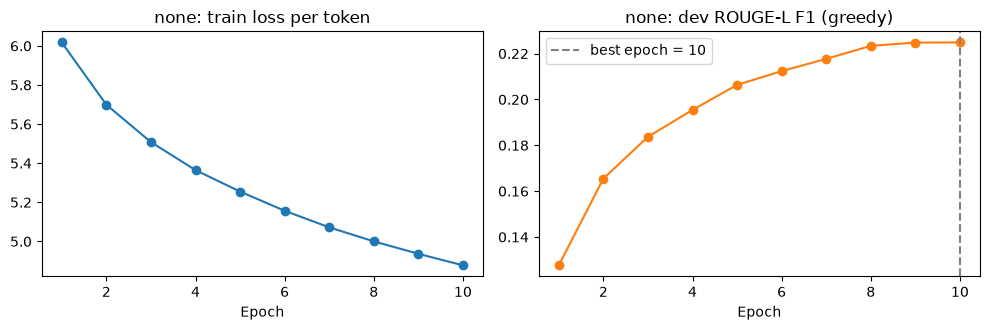

In [46]:
# Loss train và ROUGE-L dev theo epoch
plot_history('none')

In [47]:
# 3 câu dịch mẫu trên test (đúng và sai)
show_examples('none')

,loại,source,reference,hypothesis,rougeL
787,tốt,( laughter ) ( applause ) thank you .,( cười ) ( vỗ tay ) cám ơn .,( cười ) ( vỗ tay ) cảm ơn .,0.90
1208,trung bình,"people are always a combination of the two , and that combination is constantly changing .","con người luôn là một sự kết hợp của cả hai , và sự kết hợp đó liên tục thay đổi .","những người có thể có một một một những , , và và , , , và .",0.25
54,sai,v - pop prince 's documentary soundtrack among global music charts,nhạc phim tài liệu của hoàng tử v-pop lọt vào các bảng xếp hạng âm nhạc toàn cầu,<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> và <unk> .,0.00


**Nhận xét:** _(điền sau khi chạy: câu tốt/sai khác nhau ở đâu, lỗi thường gặp như lặp từ, dừng sớm, sai từ hiếm/UNK.)_

## Bài 2. Encoder–Decoder LSTM + Bahdanau attention
Ở mỗi bước, decoder dùng trạng thái bước trước làm query, chấm điểm bằng vᵀtanh(Wq + Uk) trên mọi token nguồn, lấy context rồi nối vào embedding trước khi đưa vào LSTM.

In [48]:
# Huấn luyện (tối đa 10 epoch), giữ checkpoint có ROUGE-L dev cao nhất
model = train_or_load('bahdanau')

bahdanau | số tham số: 8025763


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 1: loss=6.0485 dev_ROUGE-L=0.1342 BLEU=0.11


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 2: loss=5.6921 dev_ROUGE-L=0.1798 BLEU=0.97


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (11 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 9: loss=4.5749 dev_ROUGE-L=0.2902 BLEU=4.36


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 10: loss=4.4940 dev_ROUGE-L=0.2976 BLEU=4.49


 epoch  train_loss  dev_nll  rougeL_f1   bleu  seconds
     1      6.0485   5.9074     0.1342 0.1142 380.3752
     2      5.6921   5.5452     0.1798 0.9749 374.2373
     3      5.4126   5.2721     0.2082 1.5059 373.1082
     4      5.1991   5.0726     0.2358 2.1103 375.2465
     5      5.0278   4.9158     0.2425 2.5137 367.7004
     6      4.8887   4.7839     0.2653 3.1437 390.3203
     7      4.7690   4.6940     0.2665 3.5089 379.5317
     8      4.6614   4.6117     0.2819 3.9381 377.3574
     9      4.5749   4.5342     0.2902 4.3639 386.1522
    10      4.4940   4.4825     0.2976 4.4927 663.4890
Epoch tốt nhất (ROUGE-L dev): 10


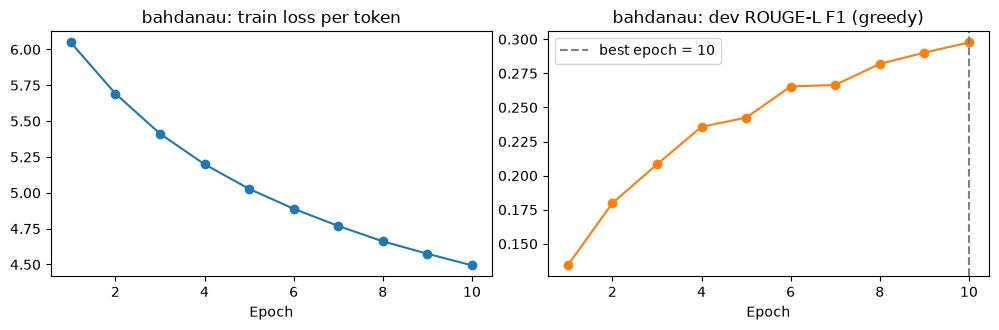

In [49]:
# Loss train và ROUGE-L dev theo epoch
plot_history('bahdanau')

In [50]:
# 3 câu dịch mẫu trên test (đúng và sai)
show_examples('bahdanau')

,loại,source,reference,hypothesis,rougeL
787,tốt,( laughter ) ( applause ) thank you .,( cười ) ( vỗ tay ) cám ơn .,( cười ) ( vỗ tay ) cảm ơn .,0.900
713,trung bình,"i mean , look , this animal is trying to fight back this spear from this soldier .","tôi muốn nói rằng , nhìn xem , con vật này đang cố chống lại mũi giáo này từ người lính này .","ý tôi là , hãy , này này này sẽ bắt đầu đến những này này này này .",0.333
54,sai,v - pop prince 's documentary soundtrack among global music charts,nhạc phim tài liệu của hoàng tử v-pop lọt vào các bảng xếp hạng âm nhạc toàn cầu,<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>,0.000


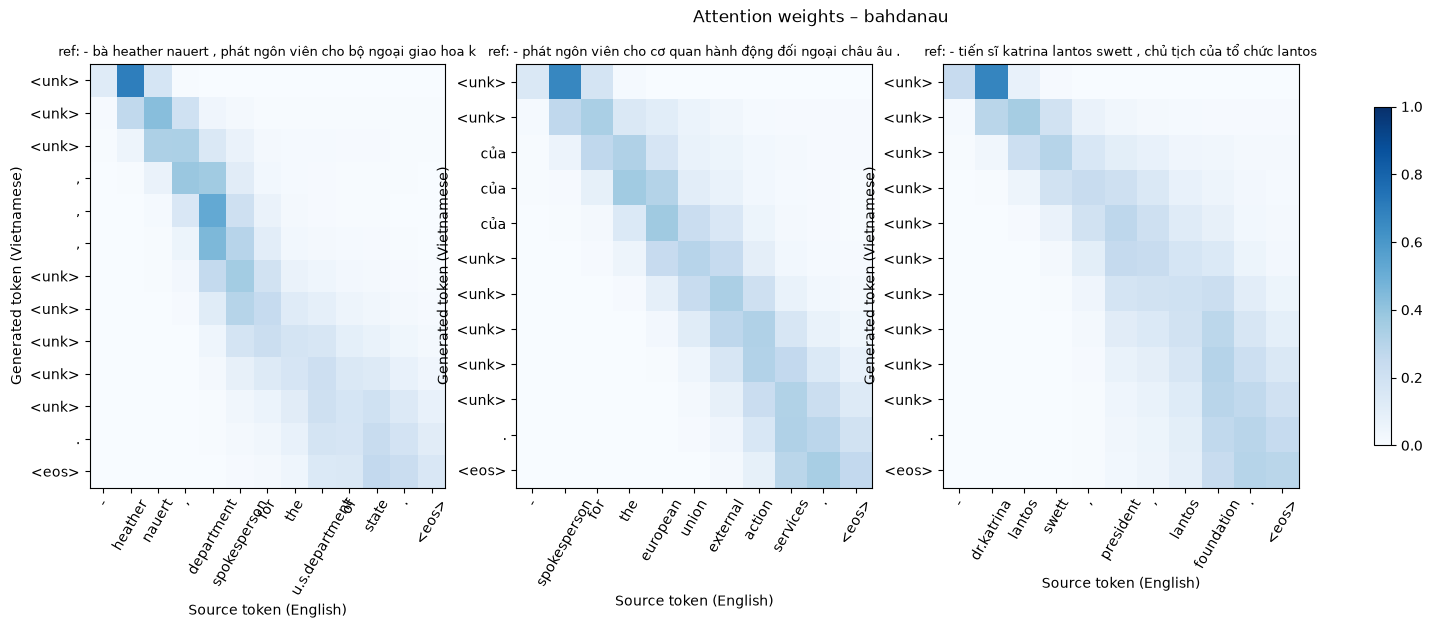

In [51]:
# Heatmap attention của 3 câu
plot_attention('bahdanau')

**Nhận xét:** _(điền sau khi chạy: câu tốt/sai khác nhau ở đâu, lỗi thường gặp như lặp từ, dừng sớm, sai từ hiếm/UNK. Nhận xét heatmap: attention có tập trung đúng từ nguồn tương ứng không, có lệch theo đường chéo không.)_

## Bài 3. Encoder–Decoder LSTM + Luong attention
LSTM cập nhật trước, dùng trạng thái hiện tại làm query với điểm general qᵀWk, ghép context với output qua tanh để dự đoán; vector này được đưa vào bước sau (input-feeding).

In [52]:
# Huấn luyện (tối đa 10 epoch), giữ checkpoint có ROUGE-L dev cao nhất
model = train_or_load('luong')

luong | số tham số: 7959971


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 1: loss=6.0628 dev_ROUGE-L=0.1297 BLEU=0.12


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 2: loss=5.7325 dev_ROUGE-L=0.1737 BLEU=0.92


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (11 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 9: loss=4.6085 dev_ROUGE-L=0.2896 BLEU=4.46


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 10: loss=4.5207 dev_ROUGE-L=0.2960 BLEU=4.84


 epoch  train_loss  dev_nll  rougeL_f1   bleu  seconds
     1      6.0628   5.9555     0.1297 0.1185 597.9461
     2      5.7325   5.6094     0.1737 0.9205 556.7880
     3      5.4617   5.3330     0.1939 1.3771 484.7138
     4      5.2518   5.1325     0.2273 1.9542 397.1018
     5      5.0799   4.9605     0.2386 2.5368 322.0878
     6      4.9350   4.8322     0.2604 3.1632 322.0852
     7      4.8138   4.7369     0.2683 3.6285 324.1146
     8      4.7013   4.6230     0.2815 4.0486 318.4955
     9      4.6085   4.5533     0.2896 4.4568 327.6693
    10      4.5207   4.4861     0.2960 4.8433 507.7962
Epoch tốt nhất (ROUGE-L dev): 10


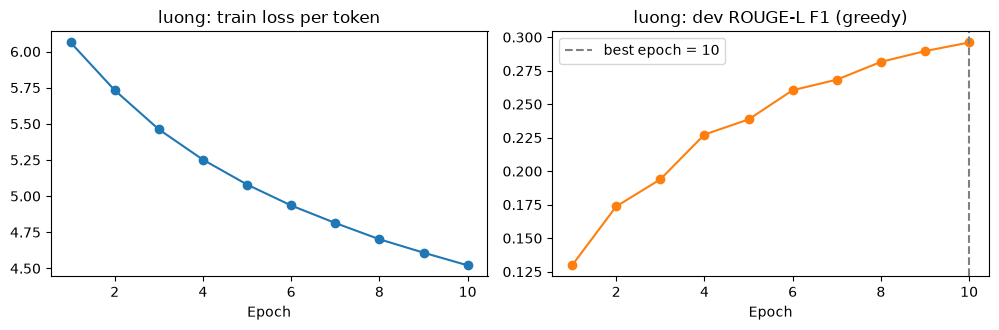

In [53]:
# Loss train và ROUGE-L dev theo epoch
plot_history('luong')

In [54]:
# 3 câu dịch mẫu trên test (đúng và sai)
show_examples('luong')

,loại,source,reference,hypothesis,rougeL
787,tốt,( laughter ) ( applause ) thank you .,( cười ) ( vỗ tay ) cám ơn .,( cười ) ( vỗ tay ) cảm ơn .,0.900
1116,trung bình,"the remains of over six million people are housed in there , some over 1,300 years old .","tàn dư của hơn 6 triệu người được lưu giữ ở đó , một số đã hơn 1300 năm tuổi .","khoảng khoảng triệu triệu triệu triệu người đã ở ở ở , trong năm năm .",0.324
63,sai,dismantling saigon 's binh trieu tollgates finished,đã hoàn thành việc tháo dỡ các trạm thu phí bình triệu ở sài gòn,<unk> <unk> <unk> <unk> <unk> <unk>,0.000


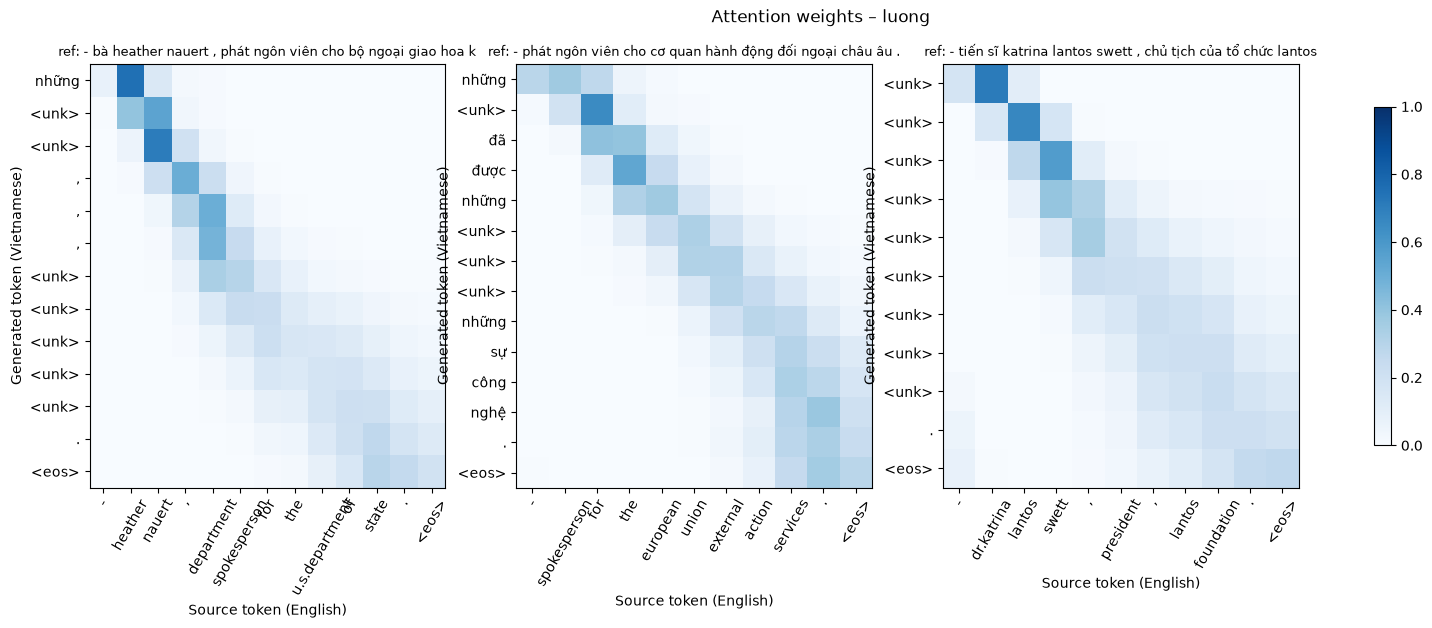

In [55]:
# Heatmap attention của 3 câu
plot_attention('luong')

**Nhận xét:** _(điền sau khi chạy: câu tốt/sai khác nhau ở đâu, lỗi thường gặp như lặp từ, dừng sớm, sai từ hiếm/UNK. Nhận xét heatmap: attention có tập trung đúng từ nguồn tương ứng không, có lệch theo đường chéo không.)_

## 3. So sánh ba mô hình
Cùng checkpoint chọn bằng dev, cùng giải mã greedy, cùng dữ liệu.

In [56]:
# Bảng so sánh ba mô hình trên dev
rows = []
for name, model in models.items():
    score = evaluate(model, dev_rows)
    seconds = np.mean([r['seconds'] for r in histories[name]])
    rows.append(dict(model=name, dev_rougeL=score['rougeL_f1'],
                     dev_bleu=score['bleu'], best_epoch=best_epochs[name],
                     parameters=sum(p.numel() for p in model.parameters()),
                     seconds_per_epoch=seconds))
comparison = pd.DataFrame(rows)
comparison.to_csv(ART/'comparison_dev.csv', index=False)
table = comparison.drop(columns='seconds_per_epoch').round(4)
print(table.to_string(index=False))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


   model  dev_rougeL  dev_bleu  best_epoch  parameters
    none      0.2248    2.0397          10     7500963
bahdanau      0.2976    4.4927          10     8025763
   luong      0.2960    4.8433          10     7959971


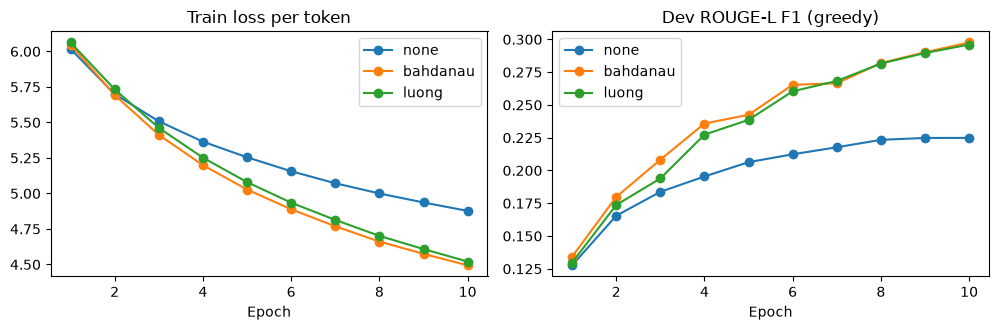

In [57]:
# Vẽ loss train và ROUGE-L dev theo epoch
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for name, records in histories.items():
    h = pd.DataFrame(records)
    axes[0].plot(h.epoch, h.train_loss, marker='o', label=name)
    axes[1].plot(h.epoch, h.rougeL_f1, marker='o', label=name)
titles = ['Train loss per token', 'Dev ROUGE-L F1 (greedy)']
for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()
fig.tight_layout()
fig.savefig(ART/'learning_curves.png', dpi=150)
plt.show()

### Chấm test một lần sau khi chốt mô hình

In [58]:
# ROUGE-L trên toàn bộ test sau lọc của ba mô hình đã chọn
results = []
for name, model in models.items():
    score = evaluate(model, filtered['test'])
    score.pop('dev_nll')
    results.append(dict(model=name, **score))
results = pd.DataFrame(results)
results.to_csv(ART/'comparison_test.csv', index=False)
print(results.drop(columns='bleu_signature').round(4).to_string(index=False))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


   model  rougeL_f1  rougeL_precision  rougeL_recall   bleu
    none     0.2328            0.2593         0.2143 2.4855
bahdanau     0.3090            0.3391         0.2876 5.2959
   luong     0.3095            0.3369         0.2905 5.7598


In [59]:
# Bảng tổng hợp kết quả (mục C.2 của đề)
labels = {'none': 'Bài 1. Không attention', 'bahdanau': 'Bài 2. Bahdanau',
          'luong': 'Bài 3. Luong'}
c, r = comparison.set_index('model'), results.set_index('model')
summary = pd.DataFrame({
    'Mô hình': [labels[m] for m in models],
    'ROUGE-L dev': [c.loc[m, 'dev_rougeL'] for m in models],
    'ROUGE-L test': [r.loc[m, 'rougeL_f1'] for m in models],
    'Số tham số': [int(c.loc[m, 'parameters']) for m in models],
    'Giây/epoch': [c.loc[m, 'seconds_per_epoch'] for m in models],
})
summary.to_csv(ART/'summary_C2.csv', index=False)
summary.round(4)

,Mô hình,ROUGE-L dev,ROUGE-L test,Số tham số,Giây/epoch
0,Bài 1. Không attention,0.2248,0.2328,7500963,247.8762
1,Bài 2. Bahdanau,0.2976,0.3090,8025763,406.7518
2,Bài 3. Luong,0.2960,0.3095,7959971,415.8798


**Nhận xét so sánh:** _(điền sau khi chạy: mô hình nào có ROUGE-L test cao nhất và vì sao; attention giúp gì với câu dài; đánh đổi số tham số và thời gian/epoch.)_

## 4. Lưu cấu hình, từ điển và kiểm tra nạp lại checkpoint

In [60]:
# Lưu cấu hình, từ điển và id các cặp đã dùng vào metadata.json
metadata = dict(config=cfg, seed=42, device=str(device),
                normalization='NFC; remove BOM; lowercase; whitespace',
                src_vocab=src_vocab, tgt_vocab=tgt_vocab, files=DATA_FILES,
                selected_train_ids=[r['id'] for r in train_rows],
                selected_dev_ids=[r['id'] for r in dev_rows],
                histories=histories, best_epochs=best_epochs)
text = json.dumps(metadata, ensure_ascii=False, indent=2)
(ART/'metadata.json').write_text(text, encoding='utf-8')
print('Đã lưu metadata.json và', len(models), 'checkpoint .pt')

Đã lưu metadata.json và 3 checkpoint .pt


In [61]:
# Nạp lại checkpoint Bahdanau và so logits với mô hình đang có
restored = make_seq2seq('bahdanau')
state = torch.load(ART/'bahdanau.pt', map_location=device, weights_only=True)
restored.load_state_dict(state)
restored.eval()
b = collate(toy)
with torch.no_grad():
    args = (b['src'].to(device), b['lengths'], b['tgt'].to(device))
    a = restored(*args, teacher_ratio=1.0)
    c = models['bahdanau'](*args, teacher_ratio=1.0)
torch.testing.assert_close(a, c)
print('Nạp lại checkpoint, từ điển và metadata: PASS')

Nạp lại checkpoint, từ điển và metadata: PASS
